# Problem 7 · Natural convection in a heated square cavity

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A square cavity filled with air has a hot left wall, a cold right wall, and insulated top and bottom walls. Nothing pushes the air, yet it starts to move: warm air rises along the hot wall, cold air sinks along the cold wall. Find the steady flow, the temperature field and the heat transferred across the cavity for Rayleigh numbers $10^3$ and $10^4$, and compare with the benchmark solution of de Vahl Davis (1983).*

Problem 6 moved the fluid with a sliding lid. Here the fluid moves **by itself**, driven by buoyancy, and the flow in turn carries the heat: **heat transfer** (Problems 1–4) and **fluid flow** (Problems 5–6) are now coupled. The same flow appears in the gap of a double-glazed window, in electronics enclosures and in rooms with a cold window and a warm wall.

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the cavity, its walls, and the Rayleigh and Prandtl numbers |
| 2 · Grid | cover the square with a 33 × 33 grid of nodes |
| 3 · Physics | add the energy equation and buoyancy to the stream function–vorticity equations of Problem 6 |
| 4 · Numerical scheme | five-point Poisson, central convection, buoyancy source, insulated walls with ghost nodes |
| 5 · Solution setup | couple three equations in one Gauss–Seidel iteration, starting from pure conduction |
| 6 · Compute | iterate for $Ra = 10^3$ and $Ra = 10^4$ |
| 7 · Post-processing | streamlines, isotherms, Nusselt number, energy balance, grid study, Richardson extrapolation, benchmark |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only imports used in the calculations are `math` and `time` (both part of Python itself). The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python
import time     # built into Python: measure the run time
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

A square cavity of side $L$ is filled with air. The left wall is held at a high temperature $T_h$, the right wall at a low temperature $T_c$; the top and bottom walls are **insulated** (no heat crosses them). Gravity points down.

Air next to the hot wall warms up, becomes lighter and rises; air next to the cold wall cools, becomes heavier and sinks. The result is one slow **clockwise** circulation that carries heat from the hot wall over the top to the cold wall. Without this flow, heat would only cross the cavity by conduction; with it, more heat is transferred.

**Dimensionless form.** As in Problem 6, the flow depends only on a few dimensionless numbers. We measure lengths in units of $L$, velocities in units of $\alpha/L$ (the thermal diffusivity $\alpha$ divided by $L$), and temperature as

$$T = \frac{T_{dim} - T_c}{T_h - T_c}, \qquad\text{so that } T = 1 \text{ on the hot wall and } T = 0 \text{ on the cold wall.}$$

Two numbers remain:

| Number | Definition | Meaning | Value |
|---|:-:|---|:-:|
| **Rayleigh number** | $Ra = \dfrac{g\,\beta\,(T_h - T_c)\,L^3}{\nu\,\alpha}$ | strength of buoyancy against viscous friction and heat diffusion | $10^3$ and $10^4$ |
| **Prandtl number** | $Pr = \nu/\alpha$ | momentum diffusion against heat diffusion | 0.71 (air) |

Here $g$ is gravity, $\beta$ the thermal expansion coefficient, $\nu$ the kinematic viscosity. What $Ra = 10^4$ means in practice:

In [2]:
Pr = 0.71                       # Prandtl number of air
Ra_values = [1e3, 1e4]          # the two Rayleigh numbers of the problem

# a real example: the air gap of a double-glazed window
g, beta = 9.81, 1 / 300         # gravity [m/s^2], expansion coefficient of air at ~300 K [1/K]
nu_air, alpha_air = 1.57e-5, 2.21e-5   # air at ~300 K [m^2/s]
dT = 10.0                       # temperature difference between the panes [K]
for L_gap in (0.010, 0.022):
    Ra_gap = g * beta * dT * L_gap**3 / (nu_air * alpha_air)
    print(f"air gap L = {L_gap * 100:.1f} cm, dT = {dT:g} K:  Ra = {Ra_gap:,.0f}")

air gap L = 1.0 cm, dT = 10 K:  Ra = 942
air gap L = 2.2 cm, dT = 10 K:  Ra = 10,035


So the two cases of this problem correspond to the air gap of a double-glazed window about 1 cm wide ($Ra \approx 10^3$) and about 2 cm wide ($Ra \approx 10^4$), with a 10 K difference between the panes.

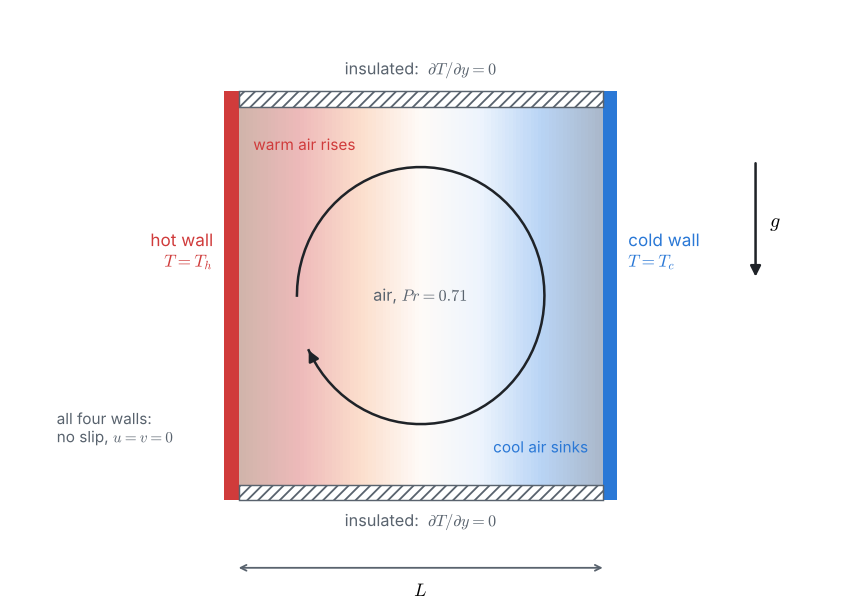

In [3]:
plots.schematic()

---
## Pillar 2 · The grid

The same uniform grid as in Problem 6: $N$ intervals per side, spacing $h = 1/N$ (in units of $L$), nodes $(i, j)$ at $x_i = i\,h$ and $y_j = j\,h$. We use $N = 32$.

The unknowns are different for each variable:

* $\psi$ and $\omega$: unknown at the $(N-1)^2$ interior nodes (as in Problem 6);
* $T$: known on the hot and cold walls, but **unknown on the insulated top and bottom walls**, so $T$ has $(N-1)(N+1)$ unknowns.

In [4]:
N = 32                    # intervals per side
h = 1 / N                 # grid spacing (in units of L)
x = [i * h for i in range(N + 1)]

print(f"N = {N}, h = {h:.5f}: unknowns per variable: psi and w {(N - 1) ** 2}, T {(N - 1) * (N + 1)}")

N = 32, h = 0.03125: unknowns per variable: psi and w 961, T 1023


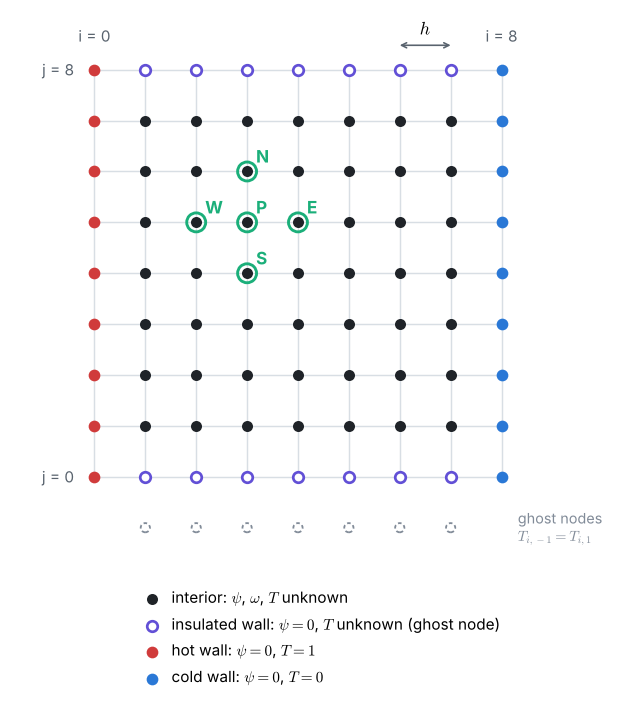

In [5]:
plots.grid(8)

---
## Pillar 3 · Physics: stream function, vorticity and temperature

We start from Problem 6: the stream function $\psi$ (with $u = \partial\psi/\partial y$, $v = -\partial\psi/\partial x$) satisfies continuity, and the vorticity $\omega = \partial v/\partial x - \partial u/\partial y$ removes the pressure. Two things are new.

**1 · Buoyancy (the Boussinesq approximation).** The density changes a little with temperature, $\rho \approx \rho_0\,[1 - \beta\,(T - T_0)]$. This small change matters only where it is multiplied by gravity, so the momentum equations get one extra term, the **buoyancy force** $g\beta(T - T_0)$ in the vertical direction. Taking the curl, as in Problem 6, it becomes a **source of vorticity** proportional to $\partial T/\partial x$: where the temperature changes sideways, the light warm fluid next to heavy cold fluid starts to turn.

**2 · The energy equation.** The temperature is carried by the flow and spreads by conduction: a convection–diffusion equation, Problem 5 in 2D.

In dimensionless form:

$$\nabla^2\psi = -\,\omega,$$

$$u\,\frac{\partial\omega}{\partial x} + v\,\frac{\partial\omega}{\partial y} = Pr\,\nabla^2\omega + \underbrace{Ra\,Pr\,\frac{\partial T}{\partial x}}_{\text{buoyancy}},$$

$$u\,\frac{\partial T}{\partial x} + v\,\frac{\partial T}{\partial y} = \nabla^2 T.$$

The three equations are **coupled both ways**: $T$ drives $\omega$ (buoyancy), $\omega$ gives $\psi$, $\psi$ gives the velocities, and the velocities carry $T$.

**Boundary conditions.**

| Wall | Flow | Temperature |
|---|---|---|
| left ($x = 0$) | no slip: $\psi = 0$, $\omega$ from Thom's formula | hot: $T = 1$ |
| right ($x = 1$) | no slip: $\psi = 0$, $\omega$ from Thom's formula | cold: $T = 0$ |
| top, bottom | no slip: $\psi = 0$, $\omega$ from Thom's formula | insulated: $\partial T/\partial y = 0$ |

All four walls are at rest, so Thom's formula of Problem 6 has no lid term: $\omega_{wall} = -2\,\psi_{adjacent}/h^2$.

**Quantity of interest: the Nusselt number.** The heat flux through the hot wall, divided by the flux that pure conduction would carry ($k\,\Delta T/L$), is the local **Nusselt number** $Nu(y) = -\,\partial T/\partial x\,|_{x=0}$. Its average over the wall tells how many times more heat crosses the cavity than by conduction alone:

$$\overline{Nu} = \int_0^1 Nu(y)\,dy.$$

Without any flow the temperature would fall linearly, $T = 1 - x$, and $\overline{Nu} = 1$.

There is no exact solution. We compare with the classic **benchmark** of G. de Vahl Davis (*International Journal for Numerical Methods in Fluids* 3, 1983, 249–264), obtained by extrapolating results from several fine grids:

In [6]:
# de Vahl Davis (1983), Pr = 0.71: |psi| at the centre, the largest u on the line x = 0.5
# (and its height y), the largest v on the line y = 0.5 (and its position x), and the average Nu
davis = {1e3: {"psi_mid": 1.174, "u_max": (3.649, 0.813), "v_max": (3.697, 0.178), "Nu": 1.118},
         1e4: {"psi_mid": 5.071, "u_max": (16.178, 0.823), "v_max": (19.617, 0.119), "Nu": 2.243}}

for Ra, d in davis.items():
    print(f"Ra = {Ra:.0e}: |psi_mid| = {d['psi_mid']}, u_max = {d['u_max'][0]} at y = {d['u_max'][1]}, "
          f"v_max = {d['v_max'][0]} at x = {d['v_max'][1]}, Nu = {d['Nu']}")

Ra = 1e+03: |psi_mid| = 1.174, u_max = 3.649 at y = 0.813, v_max = 3.697 at x = 0.178, Nu = 1.118
Ra = 1e+04: |psi_mid| = 5.071, u_max = 16.178 at y = 0.823, v_max = 19.617 at x = 0.119, Nu = 2.243


---
## Pillar 4 · Numerical scheme

The arrays are stored as rows, `psi[j][i]`, `w[j][i]`, `T[j][i]`, exactly as in Problem 6. For an interior node $P$ with neighbours $E$, $W$, $N$, $S$:

**Stream function** (five-point formula, unchanged):

$$\psi_P = \tfrac{1}{4}\left(\psi_E + \psi_W + \psi_N + \psi_S + h^2\,\omega_P\right).$$

**Vorticity** (central differences, Problem 6, now with the buoyancy source $Ra\,Pr\,(T_E - T_W)/(2h)$; the whole equation is divided by $Pr$):

$$\omega_P = \tfrac{1}{4}\Big[(1 - a_x)\,\omega_E + (1 + a_x)\,\omega_W + (1 - a_y)\,\omega_N + (1 + a_y)\,\omega_S + \tfrac{Ra\,h}{2}\,(T_E - T_W)\Big],
\qquad a_x = \frac{u_P\,h}{2\,Pr},\quad a_y = \frac{v_P\,h}{2\,Pr}.$$

**Temperature** (central differences, Problem 5 in 2D; the "diffusion coefficient" is 1):

$$T_P = \tfrac{1}{4}\Big[(1 - b_x)\,T_E + (1 + b_x)\,T_W + (1 - b_y)\,T_N + (1 + b_y)\,T_S\Big],
\qquad b_x = \frac{u_P\,h}{2},\quad b_y = \frac{v_P\,h}{2}.$$

With $u_P = (\psi_N - \psi_S)/(2h)$ and $v_P = -(\psi_E - \psi_W)/(2h)$, these coefficients come straight from $\psi$: $a_x = (\psi_N - \psi_S)/(4\,Pr)$ and $b_x = (\psi_N - \psi_S)/4$, and likewise for $a_y$ and $b_y$ with $\psi_W - \psi_E$.

**Insulated walls: ghost nodes (Problem 1).** On the bottom wall, $\partial T/\partial y = 0$. A central difference gives $(T_{i,1} - T_{i,-1})/(2h) = 0$, so the ghost node below the wall mirrors the first node above it, $T_{i,-1} = T_{i,1}$. On the wall itself the velocity is zero, so the temperature equation there is pure conduction:

$$T_{i,0} = \tfrac{1}{4}\left(T_{i+1,0} + T_{i-1,0} + 2\,T_{i,1}\right),$$

and in the same way on the top wall with $T_{i,N-1}$.

In [7]:
def wall_vorticity(psi, w, N, h):
    """Thom's formula on the four walls at rest."""
    for k in range(N + 1):
        w[0][k] = -2 * psi[1][k] / h**2          # bottom
        w[N][k] = -2 * psi[N - 1][k] / h**2      # top
        w[k][0] = -2 * psi[k][1] / h**2          # left (hot)
        w[k][N] = -2 * psi[k][N - 1] / h**2      # right (cold)

---
## Pillar 5 · Solution setup: three coupled equations in one iteration

**Starting point.** Before the fluid starts to move, heat crosses the cavity by conduction only: $T = 1 - x$, $\psi = \omega = 0$. This is a natural start, and it is where the flow is born: the sideways temperature gradient creates vorticity straight away.

**One iteration** (Gauss–Seidel, newest values always used):

1. wall vorticity from the current $\psi$ (Thom's formula);
2. one sweep of the **temperature** equation, including the insulated top and bottom walls;
3. one sweep of the **vorticity** equation, with the buoyancy source from the new $T$;
4. one sweep of the **stream function** equation, with the new $\omega$.

We stop when the largest change of $T$, $\omega$ and $\psi$ in one iteration are all below $10^{-6}$. If the numbers blow up instead (this happens on grids that are too coarse for the Rayleigh number, for example $N = 4$ at $Ra = 10^4$), the solver stops with an error message rather than returning nonsense. (We test the stream function at the centre with `math.isfinite`, because `max` silently ignores the value `nan`, "not a number", that a blown-up calculation produces.)

In [8]:
def solve_convection(N, Ra, tol=1e-6, max_iter=200_000):
    """Steady natural convection in a square cavity: Gauss-Seidel on T, w and psi."""
    h = 1 / N
    psi = [[0.0] * (N + 1) for _ in range(N + 1)]
    w = [[0.0] * (N + 1) for _ in range(N + 1)]
    T = [[1 - i * h for i in range(N + 1)] for _ in range(N + 1)]   # start: pure conduction
    changes = []                     # largest change of (T, w, psi) in every iteration

    for iteration in range(max_iter):
        # step 1: vorticity on the walls (Thom's formula)
        wall_vorticity(psi, w, N, h)

        # step 2: temperature sweep (rows 0 and N are the insulated walls)
        largest_T = 0.0
        for j in range(N + 1):
            for i in range(1, N):
                if j == 0:                                   # bottom wall, ghost node T[-1] = T[1]
                    new = (T[0][i + 1] + T[0][i - 1] + 2 * T[1][i]) / 4
                elif j == N:                                 # top wall, ghost node T[N+1] = T[N-1]
                    new = (T[N][i + 1] + T[N][i - 1] + 2 * T[N - 1][i]) / 4
                else:
                    bx = (psi[j + 1][i] - psi[j - 1][i]) / 4          # u h / 2
                    by = (psi[j][i - 1] - psi[j][i + 1]) / 4          # v h / 2
                    new = ((1 - bx) * T[j][i + 1] + (1 + bx) * T[j][i - 1]
                           + (1 - by) * T[j + 1][i] + (1 + by) * T[j - 1][i]) / 4
                largest_T = max(largest_T, abs(new - T[j][i]))
                T[j][i] = new

        # step 3: vorticity sweep, with the buoyancy source Ra h (T_E - T_W) / 2
        largest_w = 0.0
        for j in range(1, N):
            for i in range(1, N):
                ax = (psi[j + 1][i] - psi[j - 1][i]) / (4 * Pr)       # u h / (2 Pr)
                ay = (psi[j][i - 1] - psi[j][i + 1]) / (4 * Pr)       # v h / (2 Pr)
                new = ((1 - ax) * w[j][i + 1] + (1 + ax) * w[j][i - 1]
                       + (1 - ay) * w[j + 1][i] + (1 + ay) * w[j - 1][i]
                       + Ra * h / 2 * (T[j][i + 1] - T[j][i - 1])) / 4
                largest_w = max(largest_w, abs(new - w[j][i]))
                w[j][i] = new

        # step 4: stream function sweep (five-point formula)
        largest_psi = 0.0
        for j in range(1, N):
            for i in range(1, N):
                new = (psi[j][i + 1] + psi[j][i - 1] + psi[j + 1][i] + psi[j - 1][i]
                       + h * h * w[j][i]) / 4
                largest_psi = max(largest_psi, abs(new - psi[j][i]))
                psi[j][i] = new

        if not math.isfinite(psi[N // 2][N // 2]):                # the numbers blew up
            raise ArithmeticError(f"the iteration diverged after {iteration + 1} iterations")
        changes.append((largest_T, largest_w, largest_psi))
        if max(largest_T, largest_w, largest_psi) < tol:          # converged
            break

    return psi, w, T, changes

---
## Pillar 6 · Compute

In [9]:
solutions = {}
for Ra in Ra_values:
    start = time.time()
    psi, w, T, changes = solve_convection(N, Ra)
    solutions[Ra] = (psi, w, T, changes)
    print(f"Ra = {Ra:.0e}: converged after {len(changes)} iterations ({time.time() - start:.1f} s)")

Ra = 1e+03: converged after 1450 iterations (1.5 s)


Ra = 1e+04: converged after 3489 iterations (3.3 s)


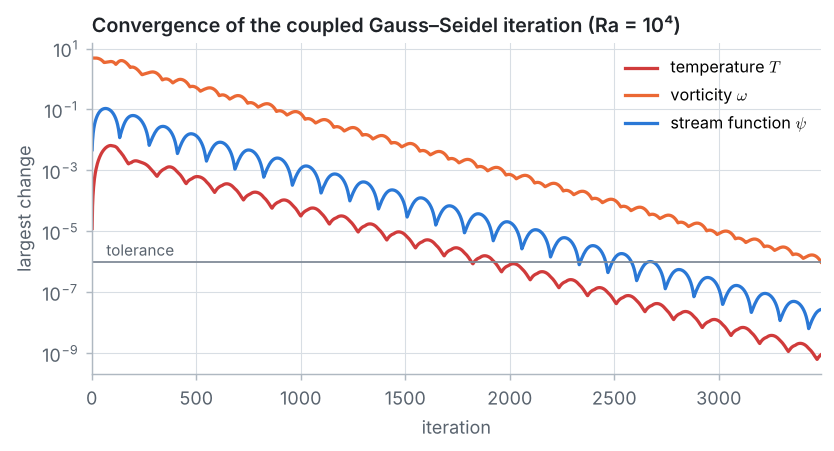

In [10]:
plots.iterations(solutions[1e4][3], 1e-6, "Ra = 10⁴")

The plot starts at iteration 2: in iteration 1 the temperature does not change at all, because the starting profile $T = 1 - x$ already satisfies the energy equation when the fluid is at rest. Buoyancy then sets the fluid in motion, the moving fluid starts to carry heat, and the three changes fall together, in slow waves, until all are below the tolerance.

### Checking the whiteboard numbers

The whiteboard guide carries out the first iteration by hand for $Ra = 10^3$ on the coarsest grid, $N = 4$. Because the iteration always starts from the same conduction state, `solve_convection(4, 1e3, max_iter=1)` returns exactly the fields after one iteration. Rows are printed from the top ($j = 4$) down to the bottom ($j = 0$):

In [11]:
def show(field, digits):
    """Print a field row by row, from the top down (+ 0.0 turns -0.0 into 0.0)."""
    for j in range(len(field) - 1, -1, -1):
        print(f"   j = {j}: " + "  ".join(f"{value + 0.0:{digits + 5}.{digits}f}" for value in field[j]))


for label, iterations in (("after iteration 1", 1), ("after iteration 2", 2), ("converged", 200_000)):
    psi_h, w_h, T_h, changes_h = solve_convection(4, 1e3, max_iter=iterations)
    print(f"N = 4, Ra = 1e3, {label} ({len(changes_h)} iterations)")
    for name, field, digits in (("temperature T", T_h, 4), ("vorticity w", w_h, 4), ("stream function psi", psi_h, 4)):
        print(f"  {name}:")
        show(field, digits)

N = 4, Ra = 1e3, after iteration 1 (1 iterations)
  temperature T:
   j = 4:    1.0000     0.7500     0.5000     0.2500     0.0000
   j = 3:    1.0000     0.7500     0.5000     0.2500     0.0000
   j = 2:    1.0000     0.7500     0.5000     0.2500     0.0000
   j = 1:    1.0000     0.7500     0.5000     0.2500     0.0000
   j = 0:    1.0000     0.7500     0.5000     0.2500     0.0000
  vorticity w:
   j = 4:    0.0000     0.0000     0.0000     0.0000     0.0000
   j = 3:    0.0000   -20.5078   -27.0996   -29.1748     0.0000
   j = 2:    0.0000   -19.5312   -25.3906   -27.0996     0.0000
   j = 1:    0.0000   -15.6250   -19.5312   -20.5078     0.0000
   j = 0:    0.0000     0.0000     0.0000     0.0000     0.0000
  stream function psi:
   j = 4:    0.0000     0.0000     0.0000     0.0000     0.0000
   j = 3:    0.0000    -0.4120    -0.6714    -0.7915     0.0000
   j = 2:    0.0000    -0.3662    -0.5798    -0.6714     0.0000
   j = 1:    0.0000    -0.2441    -0.3662    -0.4120     0.0000

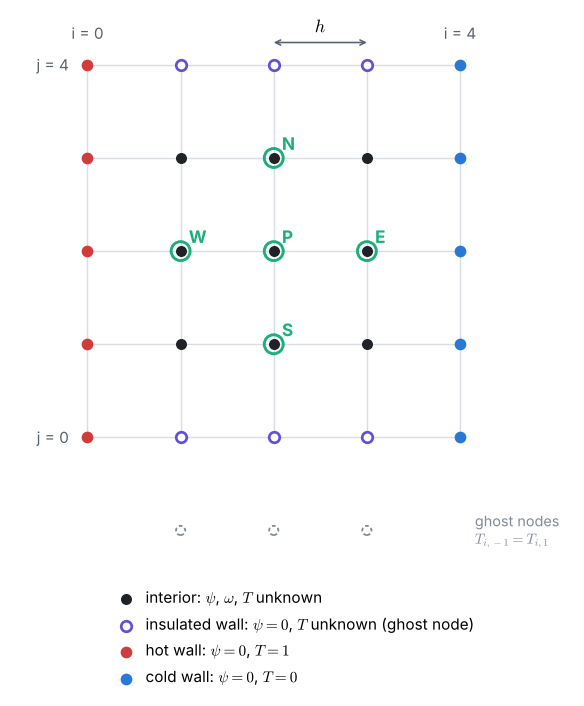

In [12]:
plots.grid(4)

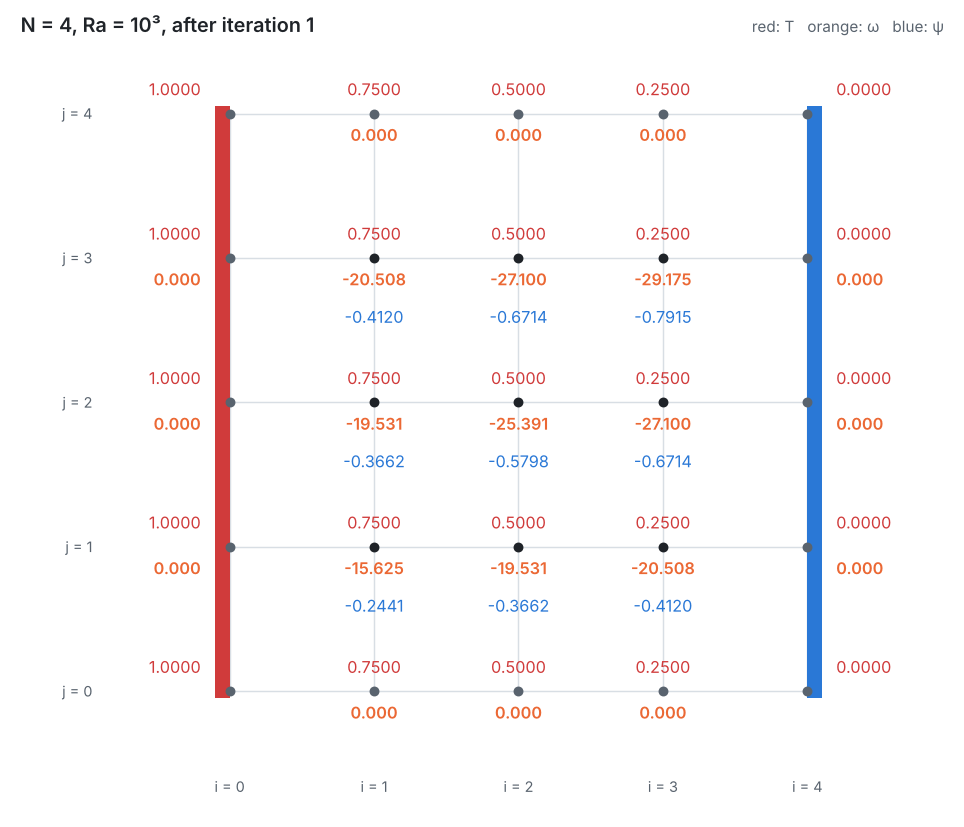

In [13]:
psi_h, w_h, T_h, _ = solve_convection(4, 1e3, max_iter=1)
plots.hand_grid(psi_h, w_h, T_h, "N = 4, Ra = 10³, after iteration 1")

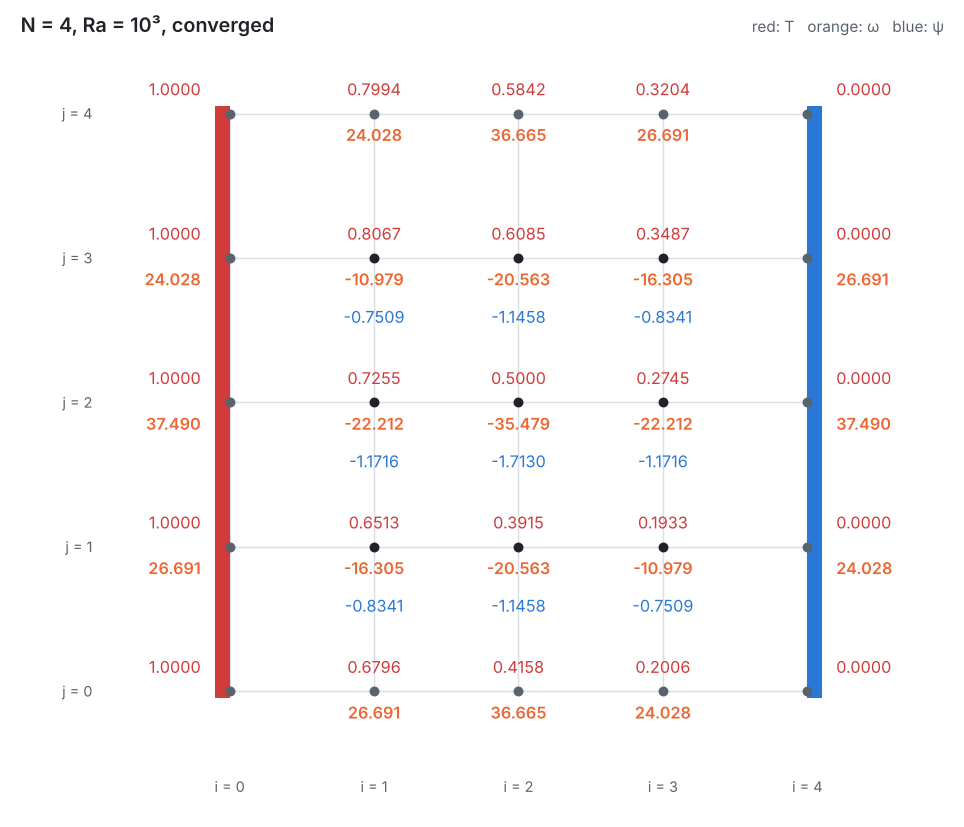

In [14]:
psi_h, w_h, T_h, _ = solve_convection(4, 1e3)
plots.hand_grid(psi_h, w_h, T_h, "N = 4, Ra = 10³, converged")

---
## Pillar 7 · Post-processing

### Streamlines and isotherms

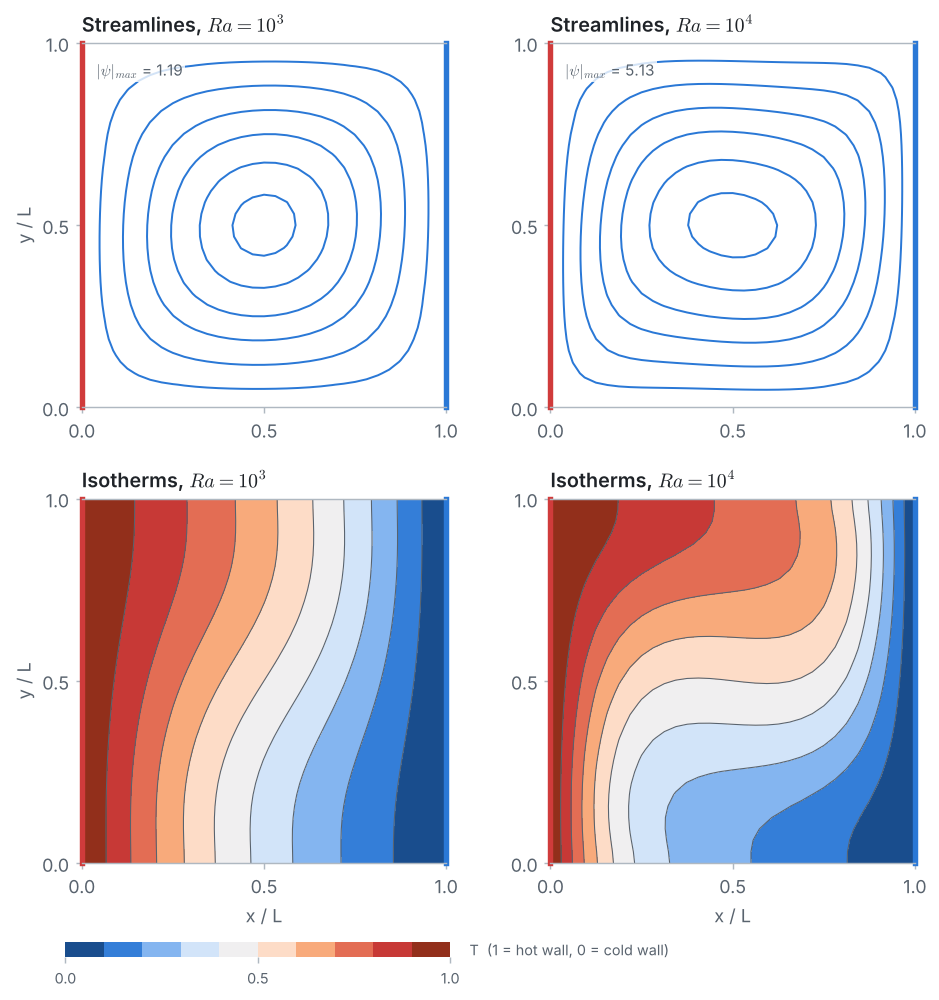

In [15]:
plots.fields(x, {Ra: solutions[Ra][:3] for Ra in Ra_values})

* At $Ra = 10^3$ the flow is weak: the isotherms are almost the vertical straight lines of pure conduction, only slightly tilted. Heat crosses the cavity mostly by conduction.
* At $Ra = 10^4$ the circulation is about four times stronger. The isotherms are strongly tilted: warm fluid is carried along the top towards the cold wall and cold fluid along the bottom towards the hot wall. The temperature drops in thin layers next to the side walls, and in the core the fluid is stratified (warm above cold).

### The Nusselt number and the energy balance

The local Nusselt number on a side wall is $-\partial T/\partial x$ there. We use a **one-sided second-order difference** (only nodes inside the cavity are available):

$$\left.\frac{\partial T}{\partial x}\right|_{x=0} \approx \frac{-3\,T_0 + 4\,T_1 - T_2}{2h}, \qquad
\left.\frac{\partial T}{\partial x}\right|_{x=1} \approx \frac{3\,T_N - 4\,T_{N-1} + T_{N-2}}{2h},$$

and average over the wall with the trapezoidal rule (Problem 1). In steady state the heat entering through the hot wall must leave through the cold wall (the top and bottom are insulated), so the two averages must agree: an **energy balance**, as in Problem 4.

In [16]:
def nusselt(T, N):
    """Local Nu along the hot and cold walls, and their averages (trapezoidal rule)."""
    h = 1 / N
    hot = [-(-3 * T[j][0] + 4 * T[j][1] - T[j][2]) / (2 * h) for j in range(N + 1)]
    cold = [-(3 * T[j][N] - 4 * T[j][N - 1] + T[j][N - 2]) / (2 * h) for j in range(N + 1)]
    average = lambda f: h * (sum(f) - (f[0] + f[-1]) / 2)
    return hot, cold, average(hot), average(cold)


for Ra in Ra_values:
    hot, cold, Nu_hot, Nu_cold = nusselt(solutions[Ra][2], N)
    j_max = max(range(N + 1), key=lambda j: hot[j])
    print(f"Ra = {Ra:.0e}: Nu hot wall {Nu_hot:.4f}, cold wall {Nu_cold:.4f}, difference {Nu_hot - Nu_cold:+.4f};"
          f"  largest local Nu {hot[j_max]:.3f} at y = {j_max * h:.3f}")

Ra = 1e+03: Nu hot wall 1.1181, cold wall 1.1181, difference +0.0000;  largest local Nu 1.506 at y = 0.094
Ra = 1e+04: Nu hot wall 2.2681, cold wall 2.2681, difference +0.0000;  largest local Nu 3.598 at y = 0.156


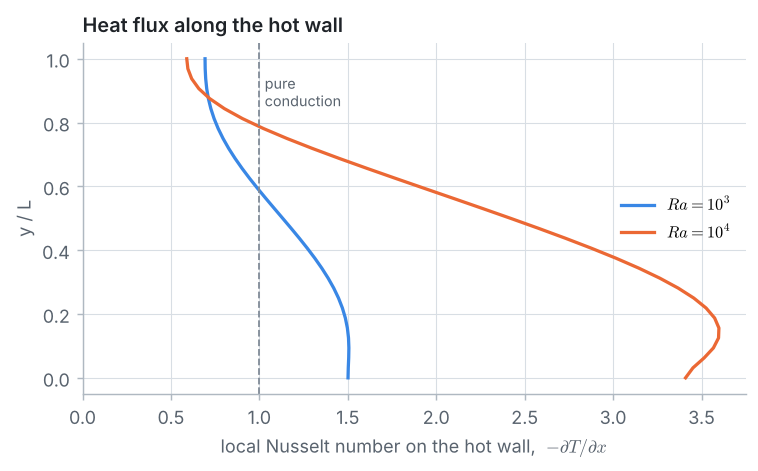

In [17]:
plots.nusselt(x, {Ra: nusselt(solutions[Ra][2], N)[0] for Ra in Ra_values})

The heat flux is largest near the **bottom** of the hot wall, where the cold fluid coming along the bottom first meets the hot wall, and smallest at the top, where the fluid arriving there has already been heated. On the cold wall it is the other way round.

The hot-wall and cold-wall averages agree to all printed decimals. They must, for two reasons: energy is conserved (Problem 4), and the problem is symmetric: turning the cavity upside down and swapping hot and cold gives exactly the same problem, so the cold wall sees the mirror image of the hot wall.

### Verification: grid study and Richardson extrapolation

We solve both cases on grids from $N = 8$ to $N = 64$. **The finest grid takes up to a minute per Rayleigh number in plain Python.**

In [18]:
def key_values(psi, T, N):
    """|psi| at the centre, largest u on x = 0.5 and v on y = 0.5 (with positions), and Nu."""
    h = 1 / N
    m = N // 2
    u_line = [((psi[j + 1][m] - psi[j - 1][m]) / (2 * h), j * h) for j in range(1, N)]
    v_line = [(-(psi[m][i + 1] - psi[m][i - 1]) / (2 * h), i * h) for i in range(1, N)]
    return {"psi_mid": abs(psi[m][m]), "u_max": max(u_line), "v_max": max(v_line),
            "Nu": nusselt(T, N)[2]}

In [19]:
grids = [8, 16, 32, 64]
study = {}
for Ra in Ra_values:
    print(f"Ra = {Ra:.0e}")
    print("    N   iterations  time [s]   |psi_mid|    u_max (y)          v_max (x)          Nu")
    study[Ra] = {}
    for n_int in grids:
        start = time.time()
        psi_n, w_n, T_n, changes_n = solve_convection(n_int, Ra)
        k = key_values(psi_n, T_n, n_int)
        study[Ra][n_int] = k
        print(f"{n_int:5d}   {len(changes_n):8d}  {time.time() - start:8.1f}   {k['psi_mid']:8.4f}"
              f"   {k['u_max'][0]:7.3f} ({k['u_max'][1]:.3f})   {k['v_max'][0]:7.3f} ({k['v_max'][1]:.3f})"
              f"   {k['Nu']:.4f}")
    d = davis[Ra]
    print(f"  de Vahl Davis          {d['psi_mid']:8.4f}   {d['u_max'][0]:7.3f} ({d['u_max'][1]:.3f})"
          f"   {d['v_max'][0]:7.3f} ({d['v_max'][1]:.3f})   {d['Nu']:.4f}")

Ra = 1e+03
    N   iterations  time [s]   |psi_mid|    u_max (y)          v_max (x)          Nu
    8        139       0.0     1.3321     3.418 (0.750)     3.411 (0.125)   1.1365


   16        445       0.1     1.2160     3.649 (0.812)     3.686 (0.188)   1.1209


   32       1450       1.5     1.1851     3.649 (0.812)     3.690 (0.188)   1.1181


   64       4510      20.1     1.1773     3.649 (0.812)     3.694 (0.172)   1.1178
  de Vahl Davis            1.1740     3.649 (0.813)     3.697 (0.178)   1.1180
Ra = 1e+04
    N   iterations  time [s]   |psi_mid|    u_max (y)          v_max (x)          Nu
    8        910       0.1     5.8428    15.080 (0.875)    18.935 (0.125)   2.8088


   16       1068       0.3     5.2880    16.209 (0.812)    19.394 (0.125)   2.3794


   32       3489       3.8     5.1288    16.165 (0.812)    19.544 (0.125)   2.2681


   64      12493      60.7     5.0876    16.180 (0.828)    19.583 (0.125)   2.2487
  de Vahl Davis            5.0710    16.178 (0.823)    19.617 (0.119)   2.2430


For a second-order scheme the error behaves like $C\,h^2$. Two grids, $h$ and $h/2$, are then enough to estimate the answer on an infinitely fine grid, a trick called **Richardson extrapolation**:

$$f_{exact} \approx f_{h/2} + \frac{f_{h/2} - f_h}{2^2 - 1} = f_{h/2} + \frac{f_{h/2} - f_h}{3}.$$

We apply it to $|\psi_{mid}|$ and $\overline{Nu}$ (quantities at fixed positions; the maxima of $u$ and $v$ jump from node to node and are not suited), and check the order with three grids: $p = \log_2\big[(f_{16} - f_{32})/(f_{32} - f_{64})\big]$.

In [20]:
print("              N = 64     extrapolated   de Vahl Davis   difference   observed order")
for Ra in Ra_values:
    s = study[Ra]
    for name in ("psi_mid", "Nu"):
        f16, f32, f64 = s[16][name], s[32][name], s[64][name]
        extrapolated = f64 + (f64 - f32) / 3
        order = math.log2((f16 - f32) / (f32 - f64))
        reference = davis[Ra][name]
        print(f"Ra = {Ra:.0e} {name:8s} {f64:8.4f}    {extrapolated:8.4f}       {reference:8.4f}"
              f"     {100 * (extrapolated - reference) / reference:+.2f} %       {order:.2f}")

              N = 64     extrapolated   de Vahl Davis   difference   observed order
Ra = 1e+03 psi_mid    1.1773      1.1747         1.1740     +0.06 %       1.97
Ra = 1e+03 Nu         1.1178      1.1177         1.1180     -0.02 %       3.30
Ra = 1e+04 psi_mid    5.0876      5.0738         5.0710     +0.06 %       1.95
Ra = 1e+04 Nu         2.2487      2.2423         2.2430     -0.03 %       2.52


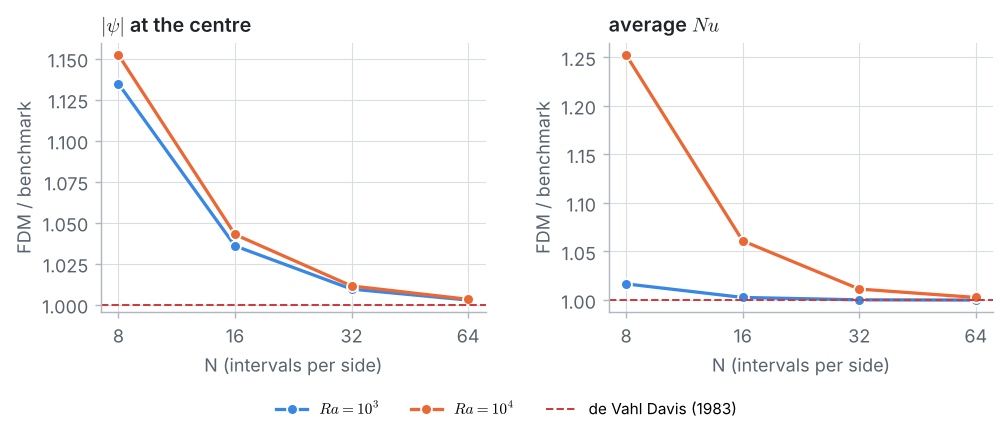

In [21]:
plots.grid_study(grids, study, davis)

* $|\psi_{mid}|$ converges with an observed order close to 2, as expected from central differences.
* For $\overline{Nu}$ the observed order is higher (3.3 and 2.5). Its changes are already very small (between $N = 32$ and $64$ only 0.0003 at $Ra = 10^3$), so the error is not yet the clean $C h^2$ of the theory; a reminder that the observed order of a real problem is only approximately the theoretical one.
* The extrapolated values agree with the de Vahl Davis benchmark to within 0.1 %, although our finest grid has only 65 × 65 nodes.
* The largest velocities converge too (table above), but their positions move from node to node, so they are compared only roughly.

### Velocity profiles

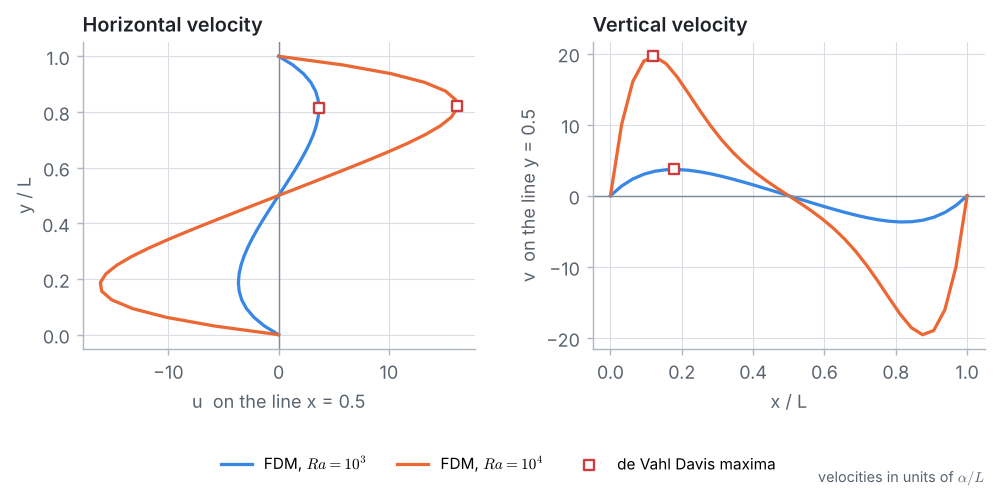

In [22]:
lines = {}
for Ra in Ra_values:
    psi, w, T, _ = solutions[Ra]
    m = N // 2
    u_line = [0.0] + [(psi[j + 1][m] - psi[j - 1][m]) / (2 * h) for j in range(1, N)] + [0.0]
    v_line = [0.0] + [-(psi[m][i + 1] - psi[m][i - 1]) / (2 * h) for i in range(1, N)] + [0.0]
    lines[Ra] = (u_line, v_line)
plots.profiles(x, lines, davis)

The horizontal velocity on the vertical centre line is positive at the top (towards the cold wall) and negative at the bottom; the vertical velocity on the horizontal centre line is positive near the hot wall (rising) and negative near the cold wall (sinking). At $Ra = 10^4$ the vertical velocity peaks very close to the walls: thin, fast **boundary layers**. The squares mark the maxima given by de Vahl Davis.

---
## Summary

* **Buoyancy** (Boussinesq approximation) adds a source $Ra\,Pr\,\partial T/\partial x$ to the vorticity equation of Problem 6, and the **energy equation** is a 2D convection–diffusion equation (Problem 5): flow and heat are coupled both ways.
* The insulated walls are handled with **ghost nodes** (Problem 1); the walls at rest get their vorticity from **Thom's formula** (Problem 6).
* One Gauss–Seidel iteration couples the three equations, starting from the pure-conduction state.
* At $Ra = 10^3$ heat crosses the cavity mostly by conduction ($\overline{Nu} \approx 1.12$); at $Ra = 10^4$ the flow more than doubles the heat transfer ($\overline{Nu} \approx 2.24$).
* A grid study shows second-order convergence, and **Richardson extrapolation** from 33 × 33 and 65 × 65 nodes reproduces the **de Vahl Davis benchmark** to within 0.1 %.

## Try it yourself

1. Set `Ra_values = [1e3, 1e4, 1e5]`. How does the flow change at $Ra = 10^5$? (de Vahl Davis: $\overline{Nu} = 4.519$. You will need a fine grid and some patience; does $N = 32$ still converge?)
2. Swap the walls (hot on the right). What happens to the sign of $\psi$ and $\omega$?
3. Replace the insulated top and bottom by walls with the conduction profile $T = 1 - x$ (a "perfectly conducting" wall). Which lines of the temperature sweep change? How does $\overline{Nu}$ change?
4. Change `Pr` to 7 (water). Does $\overline{Nu}$ change much at the same $Ra$?
5. *Challenge:* compute the Nusselt number on the vertical centre line, $\int_0^1 (u\,T - \partial T/\partial x)\,dy$ at $x = 0.5$. It must equal the wall values too. Why?